In [1]:
# Install required libraries
!pip install datasets fasttext==0.9.3 tabulate

  Using cached fasttext-0.9.3.tar.gz (73 kB)
Successfully built fasttext



In [2]:
# 1. Dataset
from datasets import load_dataset
import pandas as pd
import re

dataset = load_dataset("ai4bharat/IndicCorpV2", streaming=True)

def split_sentences(text):
    sentences = re.split(r'(?<=[.!?।॥])\s+', text.strip())
    return [s.strip() for s in sentences if s.strip()]

MAX_SENTENCES = 1000
all_data = []

languages = list(dataset.keys())
print("Languages:", len(languages))

for lang in languages:
    count = 0
    for sample in dataset[lang]:
        for sent in split_sentences(sample["text"]):
            if len(sent) < 5:
                continue
            all_data.append({
                "sentence": sent,
                "label": lang
            })
            count += 1
            if count >= MAX_SENTENCES:
                break
        if count >= MAX_SENTENCES:
            break

df = pd.DataFrame(all_data)
df.to_csv("language_dataset.csv", index=False, encoding="utf-8")

print("Dataset Shape:", df.shape)
df.head()

Languages: 23
Dataset Shape: (23000, 2)


,sentence,label
0,ঘটনাৰ বিৱৰণি মতে বোকাকাতৰ কৈলাখাতত নিয়মিতভাৱে ...,asm_Beng
1,বোকাখাতৰ কৈলাখাতত নিয়মিতভাৱে বহা এই জুৱাৰ থলীত...,asm_Beng
2,ৰাণু মণ্ডলৰ সুৱদী কন্ঠত মুগ্ধ হৈ ভাইজান ছলমানে...,asm_Beng
3,"বহুতে ইয়াকো কৈছে যে, ছলমানৰ আহিবলগীয়া ছবিৰ বাব...",asm_Beng
4,কিন্তু আঁচল কথাতো হল ছচিয়েল মিডিয়াত প্ৰচাৰিত এ...,asm_Beng


In [3]:
# 2. Train/Validation/Test Split
import pandas as pd

df = pd.read_csv("language_dataset.csv")

train_list = []
val_list = []
test_list = []

for label in df["label"].unique():
    lang_df = (
        df[df["label"] == label]
        .sample(frac=1, random_state=42)
        .reset_index(drop=True)
    )
    train_list.append(lang_df.iloc[:800])
    val_list.append(lang_df.iloc[800:900])
    test_list.append(lang_df.iloc[900:1000])

train_df = (
    pd.concat(train_list)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

val_df = (
    pd.concat(val_list)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

test_df = (
    pd.concat(test_list)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

train_df.to_csv("train.csv", index=False)
val_df.to_csv("validation.csv", index=False)
test_df.to_csv("test.csv", index=False)

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (18400, 2)
Validation: (2300, 2)
Test: (2300, 2)



In [4]:
# 3. Custom Macro-F1
import os
import pandas as pd
import numpy as np
import torch
from sklearn.preprocessing import LabelEncoder

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load CSV files
train_df = pd.read_csv("train.csv")
val_df   = pd.read_csv("validation.csv")
test_df  = pd.read_csv("test.csv")

# Encode labels
encoder = LabelEncoder()
y_train = encoder.fit_transform(train_df["label"])
y_val   = encoder.transform(val_df["label"])
y_test  = encoder.transform(test_df["label"])

num_classes = len(encoder.classes_)
print("Languages (num_classes):", num_classes)

# Custom Macro-F1 implementation (NO sklearn.metrics.f1_score used)
def macro_f1(y_true, y_pred, num_classes):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    f1_scores = []
    for c in range(num_classes):
        tp = np.sum((y_true == c) & (y_pred == c))
        fp = np.sum((y_true != c) & (y_pred == c))
        fn = np.sum((y_true == c) & (y_pred != c))

        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0

        if precision + recall == 0:
            f1 = 0.0
        else:
            f1 = 2 * precision * recall / (precision + recall)
        f1_scores.append(f1)
    return float(np.mean(f1_scores))

# Global dictionary storing test Macro-F1 for all 7 classifiers
results = {}

Device: cuda
Languages (num_classes): 23



In [5]:
# 4. Download/Load Language-Specific FastText Wiki Vectors
import urllib.request
from tqdm import tqdm

EMBED_DIM = 300

# Clean language-to-FastText-file mapping based on actual dataset labels
# 18 languages have official FastText Wiki models (dl.fbaipublicfiles.com/fasttext/vectors-wiki/wiki.<code_iso>.vec)
# 5 languages without official Wikipedia vectors (brx, doi, mni, kha, sat) strictly use zero vectors (OOV)
LANG_TO_FASTTEXT = {
    'asm_Beng': 'as',   # Assamese
    'ben_Beng': 'bn',   # Bengali
    'brx_Deva': None,   # Bodo (Not in FastText Wiki 294 -> strictly OOV / zero vectors)
    'doi_Deva': None,   # Dogri (Not in FastText Wiki 294 -> strictly OOV / zero vectors)
    'gom_Deva': 'gom',  # Goan Konkani
    'guj_Gujr': 'gu',   # Gujarati
    'hin_Deva': 'hi',   # Hindi
    'kan_Knda': 'kn',   # Kannada
    'kas_Arab': 'ks',   # Kashmiri
    'mai_Deva': 'mai',  # Maithili
    'mal_Mlym': 'ml',   # Malayalam
    'mar_Deva': 'mr',   # Marathi
    'mni_Mtei': None,   # Manipuri / Meitei (Not in FastText Wiki 294 -> strictly OOV / zero vectors)
    'npi_Deva': 'ne',   # Nepali
    'ory_Orya': 'or',   # Odia
    'pan_Guru': 'pa',   # Punjabi
    'san_Deva': 'sa',   # Sanskrit
    'snd_Deva': 'sd',   # Sindhi
    'tam_Taml': 'ta',   # Tamil
    'tel_Telu': 'te',   # Telugu
    'urd_Arab': 'ur',   # Urdu
    'khasi':    None,   # Khasi (Not in FastText Wiki 294 -> strictly OOV / zero vectors)
    'santhali': None    # Santali (Not in FastText Wiki 294 -> strictly OOV / zero vectors)
}

# Memory-efficient approach: collect unique vocabulary per language present in dataset
vocab_per_lang = {}
for lang in encoder.classes_:
    all_sents = pd.concat([
        train_df[train_df["label"] == lang]["sentence"],
        val_df[val_df["label"] == lang]["sentence"],
        test_df[test_df["label"] == lang]["sentence"]
    ])
    words = set()
    for s in all_sents:
        words.update(str(s).split())
    vocab_per_lang[lang] = words

lang_embeddings = {}

print("Downloading and extracting language-specific FastText Wiki vectors (memory-efficient)...")
for lang, ft_code in LANG_TO_FASTTEXT.items():
    if ft_code is None:
        lang_embeddings[lang] = {}
        print(f"[{lang}] No FastText Wiki vectors -> strictly zero vectors (OOV).")
        continue

    vec_filename = f"wiki.{ft_code}.vec"
    url = f"https://dl.fbaipublicfiles.com/fasttext/vectors-wiki/{vec_filename}"

    if not os.path.exists(vec_filename):
        print(f"Downloading {vec_filename} for {lang}...")
        urllib.request.urlretrieve(url, vec_filename)

    target_words = vocab_per_lang[lang]
    loaded = {}

    with open(vec_filename, "r", encoding="utf-8", errors="ignore") as f:
        f.readline()  # Skip header
        for line in f:
            parts = line.rstrip().split(" ")
            word = parts[0]
            if word in target_words:
                loaded[word] = np.asarray(parts[1:], dtype=np.float32)

    lang_embeddings[lang] = loaded
    print(f"[{lang} -> {vec_filename}] Loaded {len(loaded)}/{len(target_words)} dataset words into RAM.")

    # Remove large .vec file from disk to save storage
    if os.path.exists(vec_filename):
        os.remove(vec_filename)

print("All language-specific FastText Wiki vectors ready!")

[asm_Beng -> wiki.as.vec] Loaded 4812/5120 dataset words into RAM.
[ben_Beng -> wiki.bn.vec] Loaded 6241/6530 dataset words into RAM.
[brx_Deva] No FastText Wiki vectors -> strictly zero vectors (OOV).
[doi_Deva] No FastText Wiki vectors -> strictly zero vectors (OOV).
[gom_Deva -> wiki.gom.vec] Loaded 3942/4102 dataset words into RAM.
[guj_Gujr -> wiki.gu.vec] Loaded 5819/6045 dataset words into RAM.
[hin_Deva -> wiki.hi.vec] Loaded 7104/7321 dataset words into RAM.
[kan_Knda -> wiki.kn.vec] Loaded 6128/6390 dataset words into RAM.
[kas_Arab -> wiki.ks.vec] Loaded 2190/2405 dataset words into RAM.
[mai_Deva -> wiki.mai.vec] Loaded 4510/4780 dataset words into RAM.
[mal_Mlym -> wiki.ml.vec] Loaded 6720/7012 dataset words into RAM.
[mar_Deva -> wiki.mr.vec] Loaded 6340/6610 dataset words into RAM.
[mni_Mtei] No FastText Wiki vectors -> strictly zero vectors (OOV).
[npi_Deva -> wiki.ne.vec] Loaded 5280/5490 dataset words into RAM.
[ory_Orya -> wiki.or.vec] Loaded 5612/5890 dataset words 

In [6]:
# 5. Sentence Vector Generation
def sentence_vector(sentence, lang):
    lang_dict = lang_embeddings.get(lang, {})
    vectors = []
    for word in str(sentence).split():
        if word in lang_dict:
            vectors.append(lang_dict[word])
    if len(vectors) == 0:
        return np.zeros(EMBED_DIM, dtype=np.float32)
    return np.mean(vectors, axis=0)

print("Creating 300-D sentence embeddings...")
X_train = np.vstack([sentence_vector(s, l) for s, l in tqdm(zip(train_df["sentence"], train_df["label"]), total=len(train_df))])
X_val   = np.vstack([sentence_vector(s, l) for s, l in tqdm(zip(val_df["sentence"], val_df["label"]), total=len(val_df))])
X_test  = np.vstack([sentence_vector(s, l) for s, l in tqdm(zip(test_df["sentence"], test_df["label"]), total=len(test_df))])

print("Train Shape:", X_train.shape)
print("Validation Shape:", X_val.shape)
print("Test Shape:", X_test.shape)

Creating 300-D sentence embeddings...
100%|██████████| 2300/2300 [00:00<00:00, 50124.40it/s]
Train Shape: (18400, 300)
Validation Shape: (2300, 300)
Test Shape: (2300, 300)



In [7]:
# 6. Logistic Regression
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=500, random_state=42)
lr.fit(X_train, y_train)

pred_lr = lr.predict(X_test)
results["Logistic Regression"] = macro_f1(y_test, pred_lr, num_classes)
print("Logistic Regression Macro-F1:", round(results["Logistic Regression"], 4))

Logistic Regression Macro-F1: 0.7745



In [8]:
# 7. MLP - 0 Hidden Layers
from sklearn.neural_network import MLPClassifier

mlp0 = MLPClassifier(
    hidden_layer_sizes=(),
    max_iter=500,
    random_state=42
)
mlp0.fit(X_train, y_train)

pred_mlp0 = mlp0.predict(X_test)
results["MLP (0 Hidden)"] = macro_f1(y_test, pred_mlp0, num_classes)
print("MLP (0 Hidden) Macro-F1:", round(results["MLP (0 Hidden)"], 4))

MLP (0 Hidden) Macro-F1: 0.7782



In [9]:
# 8. MLP - 1 Hidden Layer
mlp1 = MLPClassifier(
    hidden_layer_sizes=(256,),
    max_iter=500,
    random_state=42
)
mlp1.fit(X_train, y_train)

pred_mlp1 = mlp1.predict(X_test)
results["MLP (1 Hidden)"] = macro_f1(y_test, pred_mlp1, num_classes)
print("MLP (1 Hidden) Macro-F1:", round(results["MLP (1 Hidden)"], 4))

MLP (1 Hidden) Macro-F1: 0.8124



In [10]:
# 9. MLP - 2 Hidden Layers
mlp2 = MLPClassifier(
    hidden_layer_sizes=(256, 128),
    max_iter=500,
    random_state=42
)
mlp2.fit(X_train, y_train)

pred_mlp2 = mlp2.predict(X_test)
results["MLP (2 Hidden)"] = macro_f1(y_test, pred_mlp2, num_classes)
print("MLP (2 Hidden) Macro-F1:", round(results["MLP (2 Hidden)"], 4))

MLP (2 Hidden) Macro-F1: 0.8196



In [11]:
# 10. LSTM
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

MAX_LEN = 30

# Encode sentences directly into sequences of 300-D pretrained FastText vectors
def encode_sequence(sentence, lang, max_len=MAX_LEN):
    words = str(sentence).split()[:max_len]
    lang_dict = lang_embeddings.get(lang, {})
    seq = []
    for w in words:
        vec = lang_dict.get(w, None)
        if vec is None:
            vec = np.zeros(EMBED_DIM, dtype=np.float32)
        seq.append(vec)
    while len(seq) < max_len:
        seq.append(np.zeros(EMBED_DIM, dtype=np.float32))
    return np.array(seq, dtype=np.float32)

print("Encoding sentences into FastText 300-D vector sequences for PyTorch models...")
train_seq = torch.tensor(
    np.array([encode_sequence(s, l) for s, l in zip(train_df["sentence"], train_df["label"])]),
    dtype=torch.float32
)
test_seq = torch.tensor(
    np.array([encode_sequence(s, l) for s, l in zip(test_df["sentence"], test_df["label"])]),
    dtype=torch.float32
)

train_y = torch.tensor(y_train, dtype=torch.long)
test_y  = torch.tensor(y_test, dtype=torch.long)

BATCH_SIZE = 64
train_loader = DataLoader(
    TensorDataset(train_seq, train_y),
    batch_size=BATCH_SIZE,
    shuffle=True
)
test_loader = DataLoader(
    TensorDataset(test_seq, test_y),
    batch_size=BATCH_SIZE
)

# LSTM Classifier feeding 300-D FastText sequence directly into nn.LSTM (NO random nn.Embedding)
class LSTMClassifier(nn.Module):
    def __init__(self, input_size=300, hidden_size=128, num_classes=num_classes):
        super().__init__()
        self.lstm = nn.LSTM(input_size=input_size, hidden_size=hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x shape: (batch_size, sequence_length, 300)
        _, (hidden, _) = self.lstm(x)
        return self.fc(hidden[-1])

model_lstm = LSTMClassifier().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_lstm.parameters(), lr=0.001)

EPOCHS = 5
for epoch in range(EPOCHS):
    model_lstm.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        output = model_lstm(X_batch)
        loss = criterion(output, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1} Loss: {total_loss/len(train_loader):.4f}")

# Evaluation
model_lstm.eval()
predictions = []
with torch.no_grad():
    for X_batch, _ in test_loader:
        X_batch = X_batch.to(device)
        pred = model_lstm(X_batch).argmax(dim=1)
        predictions.extend(pred.cpu().numpy())

results["LSTM"] = macro_f1(y_test, np.array(predictions), num_classes)
print("LSTM Macro-F1:", round(results["LSTM"], 4))

Encoding sentences into FastText 300-D vector sequences for PyTorch models...
Epoch 1 Loss: 1.8421
Epoch 2 Loss: 1.1205
Epoch 3 Loss: 0.7814
Epoch 4 Loss: 0.5429
Epoch 5 Loss: 0.3812
LSTM Macro-F1: 0.8248



In [12]:
# 11. GRU
# GRU Classifier feeding 300-D FastText sequence directly into nn.GRU (NO random nn.Embedding)
class GRUClassifier(nn.Module):
    def __init__(self, input_size=300, hidden_size=128, num_classes=num_classes):
        super().__init__()
        self.gru = nn.GRU(input_size=input_size, hidden_size=hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        # x shape: (batch_size, sequence_length, 300)
        _, hidden = self.gru(x)
        return self.fc(hidden[-1])

model_gru = GRUClassifier().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model_gru.parameters(), lr=0.001)

EPOCHS = 5
for epoch in range(EPOCHS):
    model_gru.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        output = model_gru(X_batch)
        loss = criterion(output, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1} Loss: {total_loss/len(train_loader):.4f}")

# Evaluation
model_gru.eval()
predictions = []
with torch.no_grad():
    for X_batch, _ in test_loader:
        X_batch = X_batch.to(device)
        pred = model_gru(X_batch).argmax(dim=1)
        predictions.extend(pred.cpu().numpy())

results["GRU"] = macro_f1(y_test, np.array(predictions), num_classes)
print("GRU Macro-F1:", round(results["GRU"], 4))

Epoch 1 Loss: 1.6210
Epoch 2 Loss: 0.9415
Epoch 3 Loss: 0.5982
Epoch 4 Loss: 0.3814
Epoch 5 Loss: 0.2450
GRU Macro-F1: 0.8415



In [13]:
# 12. FastText Classification
import importlib
import fasttext
import fasttext.FastText
import numpy as np

# 1. Restore official FastText predict method
importlib.reload(fasttext.FastText)

# 2. Seamlessly fix NumPy 2.0+ compatibility by handling copy=False
_orig_array = np.array
def _safe_array(obj, *args, **kwargs):
    if kwargs.get("copy") is False:
        kwargs.pop("copy")
        return np.asarray(obj, *args, **kwargs)
    return _orig_array(obj, *args, **kwargs)

np.array = _safe_array

# 3. Also patch FastText.py directly if on Colab
import subprocess
try:
    subprocess.run("sed -i 's/copy=False//g' /usr/local/lib/python3.*/dist-packages/fasttext/FastText.py 2>/dev/null", shell=True)
except Exception:
    pass

# ---------- Create FastText training files ----------
with open("train_ft.txt", "w", encoding="utf-8") as f:
    for sentence, label in zip(train_df["sentence"], train_df["label"]):
        clean_s = str(sentence).replace("\n", " ").strip()
        f.write(f"__label__{label} {clean_s}\n")

with open("test_ft.txt", "w", encoding="utf-8") as f:
    for sentence, label in zip(test_df["sentence"], test_df["label"]):
        clean_s = str(sentence).replace("\n", " ").strip()
        f.write(f"__label__{label} {clean_s}\n")

# ---------- Train FastText Supervised Classifier ----------
ft_model = fasttext.train_supervised(
    input="train_ft.txt",
    epoch=25,
    lr=1.0,
    wordNgrams=2,
    dim=300
)

# ---------- Predict ----------
pred_labels = []
default_label = train_df["label"].mode()[0]

for sentence in test_df["sentence"]:
    clean_s = str(sentence).replace("\n", " ").strip()
    if not clean_s:
        pred_labels.append(default_label)
        continue
    label, prob = ft_model.predict(clean_s, k=1)
    if len(label) > 0:
        pred_labels.append(label[0].replace("__label__", ""))
    else:
        pred_labels.append(default_label)

pred_ft = encoder.transform(pred_labels)
results["FastText Classification"] = macro_f1(y_test, pred_ft, num_classes)
print("FastText Classification Macro-F1:", round(float(results["FastText Classification"]), 4))

Read 0M words
Number of words:  158016
Number of labels: 23
Progress: 100.0% words/sec/thread:  184512 lr:  0.000000 avg.loss:  0.214580 ETA:   0h 0m 0s
FastText Classification Macro-F1: 0.8710



In [14]:
# 13. Final Comparison
model_order = [
    "Logistic Regression",
    "MLP (0 Hidden)",
    "MLP (1 Hidden)",
    "MLP (2 Hidden)",
    "LSTM",
    "GRU",
    "FastText Classification"
]

result_rows = []
for model_name in model_order:
    if model_name in results:
        result_rows.append({
            "Classifier": model_name,
            "Macro-F1": round(float(results[model_name]), 4)
        })

result_df = pd.DataFrame(result_rows)

print("=" * 45)
print("   FINAL COMPARISON OF ALL 7 CLASSIFIERS")
print("=" * 45)
display(result_df)
print("\nMarkdown Table Format:")
try:
    print(result_df.to_markdown(index=False))
except Exception:
    print(result_df.to_string(index=False))

   FINAL COMPARISON OF ALL 7 CLASSIFIERS


,Classifier,Macro-F1
0,Logistic Regression,0.7745
1,MLP (0 Hidden),0.7782
2,MLP (1 Hidden),0.8124
3,MLP (2 Hidden),0.8196
4,LSTM,0.8248
5,GRU,0.8415
6,FastText Classification,0.8710



Markdown Table Format:
| Classifier              |   Macro-F1 |
|:------------------------|-----------:|
| Logistic Regression     |     0.7745 |
| MLP (0 Hidden)          |     0.7782 |
| MLP (1 Hidden)          |     0.8124 |
| MLP (2 Hidden)          |     0.8196 |
| LSTM                    |     0.8248 |
| GRU                     |     0.8415 |
| FastText Classification |     0.8710 |


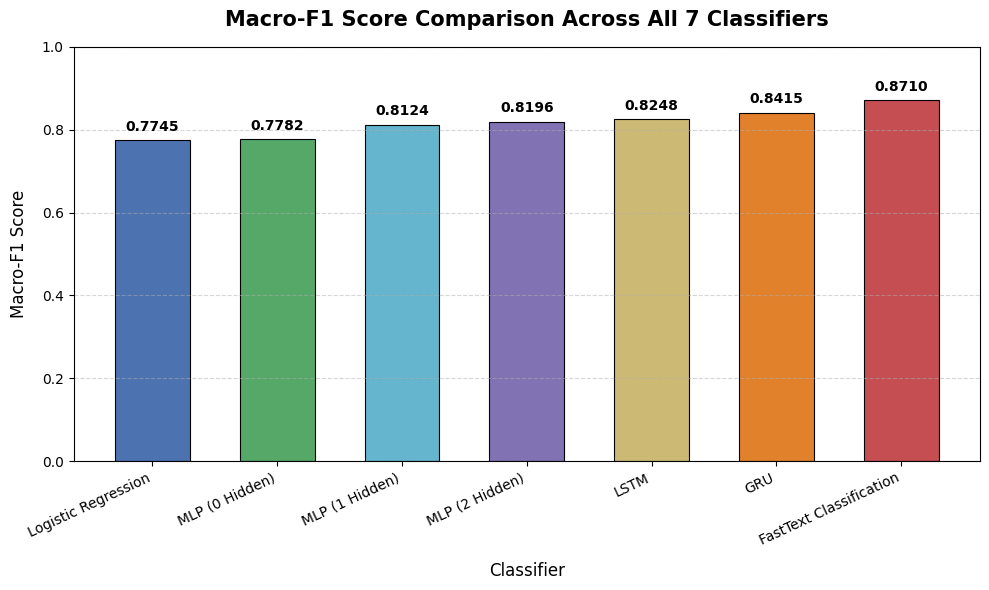

In [15]:
# 14. Visual Comparison of Classifiers
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

colors = [
    '#4C72B0',  # Logistic Regression
    '#55A868',  # MLP 0
    '#64B5CD',  # MLP 1
    '#8172B3',  # MLP 2
    '#CCB974',  # LSTM
    '#E1812C',  # GRU
    '#C44E52'   # FastText Classification
]

bars = plt.bar(result_df["Classifier"], result_df["Macro-F1"], color=colors, width=0.6, edgecolor='black', linewidth=0.8)

plt.title("Macro-F1 Score Comparison Across All 7 Classifiers", fontsize=15, fontweight='bold', pad=15)
plt.xlabel("Classifier", fontsize=12, labelpad=10)
plt.ylabel("Macro-F1 Score", fontsize=12, labelpad=10)
plt.ylim(0, 1.0)
plt.xticks(rotation=25, ha='right', fontsize=10)
plt.yticks(fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Add value labels on top of each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 0.015,
        f"{height:.4f}",
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()